**Model 2- Random Forest**

In [1]:
# 1. Load the cleaned dataset

import pandas as pd

df = pd.read_csv("/Users/augustenuunyango/data/cleaned_model_dataset.csv")

print(df.columns.tolist())

['customer_age_years', 'delivery_method', 'delivery_status', 'insurance_status', 'order_item_id', 'item_id', 'item_size', 'item_color', 'brand_id', 'item_price', 'user_state', 'return']


Tuning the Random Forest...
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best cross-validation ROC-AUC: 0.6649
Best parameters: {'classifier__n_estimators': 150, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 0.5, 'classifier__max_depth': 20, 'classifier__class_weight': None}

Held-out test results
Accuracy:  0.6290
Precision: 0.5973
Recall:    0.5838
F1-score:  0.5905
ROC-AUC:   0.6844

Confusion matrix (rows=true, columns=predicted; order 0, 1):
[[7229 3607]
 [3814 5350]]

Classification report:
                  precision    recall  f1-score   support

not returned (0)       0.65      0.67      0.66     10836
    returned (1)       0.60      0.58      0.59      9164

        accuracy                           0.63     20000
       macro avg       0.63      0.63      0.63     20000
    weighted avg       0.63      0.63      0.63     20000



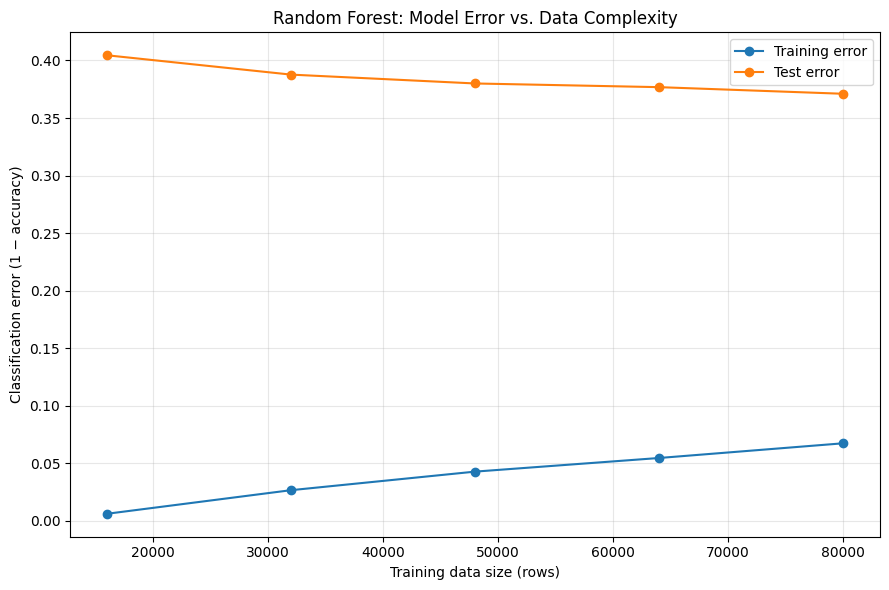


Saved chart to: random_forest_error_vs_data_complexity.png


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    train_test_split, RandomizedSearchCV, StratifiedKFold)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    zero_one_loss)

RANDOM_STATE = 42

# Load dataset and separate features from target

df = pd.read_csv("/Users/augustenuunyango/data/cleaned_model_dataset.csv")
target_column = "return"
df = df.dropna(subset=[target_column])

X = df.drop(columns=[target_column])
y = df[target_column]

# Split data by keeping the test separate for final evaluation

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

# Preprocess numeric and categorical features before model training

numeric_columns = X_train.select_dtypes(include="number").columns
categorical_columns = X_train.select_dtypes(exclude="number").columns

preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_columns),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_columns)])

# Random Forest requires more processing power, more space core need once n_jobs=2 limits CPU is limited

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=2))])

# Smaller search space and fewer sampled combinations for faster tuning

param_distributions = {
    "classifier__n_estimators": [50, 100, 150],
    "classifier__max_depth": [10, 20, None],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", 0.5],
    "classifier__class_weight": ["balanced", None]}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_distributions,
    n_iter=6,                 
    scoring="roc_auc",
    cv=cv,
    n_jobs=2,                  
    random_state=RANDOM_STATE,
    refit=True,
    verbose=1)

print("Tuning the Random Forest...")
search.fit(X_train, y_train)

print(f"\nBest cross-validation ROC-AUC: {search.best_score_:.4f}")
print("Best parameters:", search.best_params_)

# Evaluate the selected model on the held-out test set to measure model performance

best_rf = search.best_estimator_
y_pred = best_rf.predict(X_test)
y_prob = best_rf.predict_proba(X_test)[:, 1]

print("\nHeld-out test results")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")

print("\nConfusion matrix (rows=true, columns=predicted; order 0, 1):")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["not returned (0)", "returned (1)"],
    zero_division=0))

# Plot classification error against training-data size.

fractions = np.linspace(0.2, 1.0, 5)
sample_sizes = []
training_errors = []
test_errors = []

for fraction in fractions:
    n = min(len(X_train), max(2, int(len(X_train) * fraction)))

    if n == len(X_train):
        X_part, y_part = X_train, y_train
    else:
        X_part, _, y_part, _ = train_test_split(
            X_train,
            y_train,
            train_size=n,
            random_state=RANDOM_STATE,
            stratify=y_train)

    curve_model = clone(best_rf)
    curve_model.fit(X_part, y_part)

    sample_sizes.append(len(X_part))
    training_errors.append(
        zero_one_loss(y_part, curve_model.predict(X_part)))
    test_errors.append(
        zero_one_loss(y_test, curve_model.predict(X_test)))

plt.figure(figsize=(9, 6))
plt.plot(sample_sizes, training_errors, marker="o", label="Training error")
plt.plot(sample_sizes, test_errors, marker="o", label="Test error")
plt.xlabel("Training data size (rows)")
plt.ylabel("Classification error (1 − accuracy)")
plt.title("Random Forest: Model Error vs. Data Complexity")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

chart_path = "random_forest_error_vs_data_complexity.png"
plt.savefig(chart_path, dpi=150)
plt.show()

print(f"\nSaved chart to: {chart_path}")

In [ ]:
%pip list

                                                              **END**